In [48]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.naive_bayes import GaussianNB
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn import mixture
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

In [15]:
peng = sns.load_dataset('penguins')
peng

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female
...,...,...,...,...,...,...,...
339,Gentoo,Biscoe,NaN,NaN,NaN,NaN,NaN
340,Gentoo,Biscoe,46.8,14.3,215.0,4850.0,Female
341,Gentoo,Biscoe,50.4,15.7,222.0,5750.0,Male
342,Gentoo,Biscoe,45.2,14.8,212.0,5200.0,Female


In [16]:
new_da = peng.bfill()

In [17]:
new_da

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
3,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female
...,...,...,...,...,...,...,...
339,Gentoo,Biscoe,46.8,14.3,215.0,4850.0,Female
340,Gentoo,Biscoe,46.8,14.3,215.0,4850.0,Female
341,Gentoo,Biscoe,50.4,15.7,222.0,5750.0,Male
342,Gentoo,Biscoe,45.2,14.8,212.0,5200.0,Female


In [18]:
X = new_da.drop(['sex', 'species', 'island'], axis= 1)
X

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
0,39.1,18.7,181.0,3750.0
1,39.5,17.4,186.0,3800.0
2,40.3,18.0,195.0,3250.0
3,36.7,19.3,193.0,3450.0
4,36.7,19.3,193.0,3450.0
...,...,...,...,...
339,46.8,14.3,215.0,4850.0
340,46.8,14.3,215.0,4850.0
341,50.4,15.7,222.0,5750.0
342,45.2,14.8,212.0,5200.0


In [6]:
y = new_da['species']
y

0      Adelie
1      Adelie
2      Adelie
3      Adelie
4      Adelie
        ...  
339    Gentoo
340    Gentoo
341    Gentoo
342    Gentoo
343    Gentoo
Name: species, Length: 344, dtype: object

In [7]:
Xtrain, Xtest, ytrain, ytest = train_test_split(X, y, random_state=1, train_size=0.8)

In [8]:
model = GaussianNB() # 2. instantiate model
model.fit(Xtrain, ytrain) # 3. fit model to data
y_model = model.predict(Xtest) # 4. predict on new data

In [9]:
print("Predicted \n", y_model)
print("Original label \n", ytest.values)

Predicted 
 ['Gentoo' 'Gentoo' 'Gentoo' 'Adelie' 'Gentoo' 'Gentoo' 'Adelie' 'Adelie'
 'Adelie' 'Gentoo' 'Chinstrap' 'Gentoo' 'Gentoo' 'Chinstrap' 'Adelie'
 'Adelie' 'Adelie' 'Gentoo' 'Adelie' 'Adelie' 'Gentoo' 'Chinstrap'
 'Gentoo' 'Gentoo' 'Adelie' 'Adelie' 'Chinstrap' 'Chinstrap' 'Gentoo'
 'Adelie' 'Adelie' 'Adelie' 'Gentoo' 'Adelie' 'Adelie' 'Adelie' 'Adelie'
 'Adelie' 'Gentoo' 'Adelie' 'Adelie' 'Adelie' 'Adelie' 'Gentoo' 'Gentoo'
 'Gentoo' 'Adelie' 'Gentoo' 'Chinstrap' 'Chinstrap' 'Chinstrap'
 'Chinstrap' 'Adelie' 'Adelie' 'Gentoo' 'Chinstrap' 'Gentoo' 'Chinstrap'
 'Adelie' 'Adelie' 'Gentoo' 'Adelie' 'Gentoo' 'Gentoo' 'Adelie' 'Adelie'
 'Adelie' 'Chinstrap' 'Adelie']
Original label 
 ['Gentoo' 'Gentoo' 'Gentoo' 'Adelie' 'Gentoo' 'Gentoo' 'Adelie' 'Adelie'
 'Adelie' 'Gentoo' 'Chinstrap' 'Gentoo' 'Gentoo' 'Chinstrap' 'Adelie'
 'Adelie' 'Adelie' 'Gentoo' 'Adelie' 'Adelie' 'Gentoo' 'Chinstrap'
 'Gentoo' 'Gentoo' 'Adelie' 'Adelie' 'Chinstrap' 'Chinstrap' 'Gentoo'
 'Adelie' 'Adelie' 'Ade

In [10]:
from sklearn.metrics import accuracy_score
accuracy_score(ytest, y_model)

0.9565217391304348

In [11]:
X

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
0,39.1,18.7,181.0,3750.0
1,39.5,17.4,186.0,3800.0
2,40.3,18.0,195.0,3250.0
3,36.7,19.3,193.0,3450.0
4,36.7,19.3,193.0,3450.0
...,...,...,...,...
339,46.8,14.3,215.0,4850.0
340,46.8,14.3,215.0,4850.0
341,50.4,15.7,222.0,5750.0
342,45.2,14.8,212.0,5200.0


In [12]:
model = PCA(n_components=3)
model.fit(X)
X_r = model.transform(X)

In [13]:
X_r[:10]

array([[-4.51722632e+02, -1.33534716e+01,  1.15565518e+00],
       [-4.01649386e+02, -9.16820244e+00, -7.69338273e-02],
       [-9.51440261e+02,  8.25161064e+00, -2.31345609e+00],
       [-7.51512101e+02,  1.96777026e+00, -4.78543625e+00],
       [-7.51512101e+02,  1.96777026e+00, -4.78543625e+00],
       [-5.51574005e+02, -3.35767891e+00, -1.10277842e+00],
       [-5.76706686e+02, -1.13550307e+01,  7.38338060e-01],
       [ 4.73374366e+02, -1.47835216e+01, -1.98497012e+00],
       [-7.26524407e+02,  8.81936505e-01, -7.39439979e+00],
       [ 4.83620642e+01, -1.19870717e+01,  1.87307284e+00]])

In [14]:
new_da["PCA1"] = X_r[:, 0]
new_da["PCA2"] = X_r[:, 1]

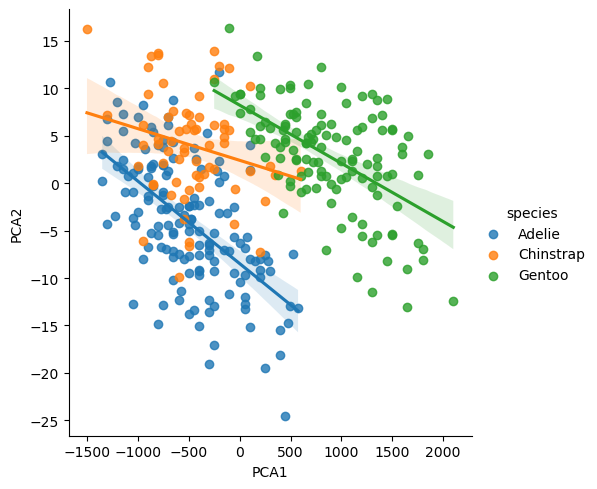

In [15]:
sns.lmplot(x="PCA1", y="PCA2", hue='species', data=new_da, fit_reg=True)
plt.show()

In [16]:
X

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
0,39.1,18.7,181.0,3750.0
1,39.5,17.4,186.0,3800.0
2,40.3,18.0,195.0,3250.0
3,36.7,19.3,193.0,3450.0
4,36.7,19.3,193.0,3450.0
...,...,...,...,...
339,46.8,14.3,215.0,4850.0
340,46.8,14.3,215.0,4850.0
341,50.4,15.7,222.0,5750.0
342,45.2,14.8,212.0,5200.0


In [17]:
model = mixture.GaussianMixture(n_components=3, covariance_type='full')
model.fit(X)
y = model.predict(X)
y

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,

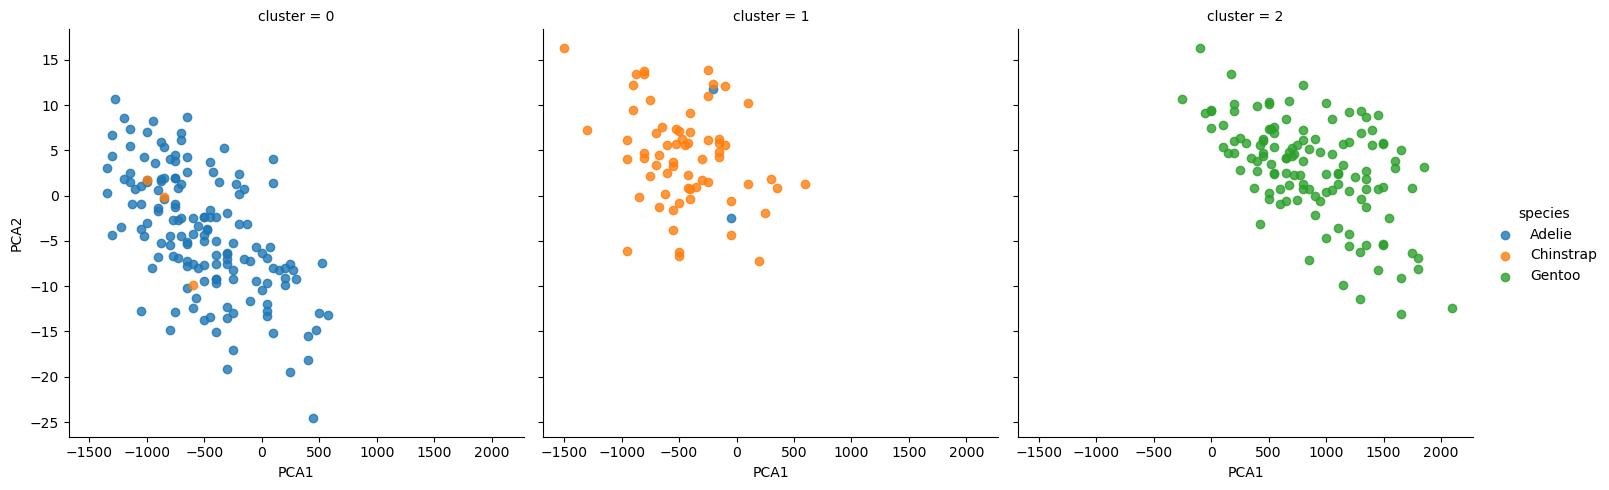

In [18]:
new_da['cluster'] = y
sns.lmplot(x ="PCA1", y ="PCA2", data=new_da, hue='species', col='cluster', fit_reg=False);
plt.show()

# GridSearchCV

In [37]:
import warnings
warnings.filterwarnings('ignore')


logistic = LogisticRegression(solver='saga')

penalty = ['l1', 'l2']

C = np.logspace(0, 4, 10)

hyperparameters = dict(C=C, penalty=penalty)

gridsearch = GridSearchCV(logistic, hyperparameters, cv=5, verbose=0)

best_model = gridsearch.fit(Xtrain, ytrain)
best_model

GridSearchCV(cv=5, estimator=LogisticRegression(solver='saga'),
             param_grid={'C': array([1.00000000e+00, 2.78255940e+00, 7.74263683e+00, 2.15443469e+01,
       5.99484250e+01, 1.66810054e+02, 4.64158883e+02, 1.29154967e+03,
       3.59381366e+03, 1.00000000e+04]),
                         'penalty': ['l1', 'l2']})

In [22]:
print('Best Penalty:', best_model.best_estimator_.get_params()['penalty'])
print('Best C:', best_model.best_estimator_.get_params()['C'])

Best Penalty: l1
Best C: 1.0


In [49]:
ygrid = best_model.predict(Xtest)

In [46]:
acc = cross_val_score(gridsearch, X, y).mean()
acc

np.float64(0.6600596760443308)

In [50]:
accuracy_score(ytest,ygrid)

0.9855072463768116

# Randomized Search CV

In [34]:
from scipy.stats import uniform

In [42]:
logistic = LogisticRegression()

penalty = ['l1', 'l2']

C = uniform(loc=0, scale=4)

hyperparameters = dict(C=C, penalty=penalty)

randomizedsearch = RandomizedSearchCV(logistic, hyperparameters, random_state=1, n_iter=100, 
                                      cv=5, verbose=0, n_jobs=-1)

best_model = randomizedsearch.fit(Xtrain, ytrain)
best_model

RandomizedSearchCV(cv=5, estimator=LogisticRegression(), n_iter=100, n_jobs=-1,
                   param_distributions={'C': <scipy.stats._distn_infrastructure.rv_continuous_frozen object at 0x000002383E693390>,
                                        'penalty': ['l1', 'l2']},
                   random_state=1)

In [51]:
yrand = best_model.predict(Xtest)

In [47]:
cross_val_score(randomizedsearch, X, y).mean()

np.float64(0.9854646206308612)

In [52]:
accuracy_score(ytest,yrand)

0.9855072463768116